                       name    year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007.0          60000    70000.0  Petrol   
1  Maruti Wagon R LXI Minor  2007.0         135000    50000.0  Petrol   
2      Hyundai Verna 1.6 SX  2012.0         600000   100000.0  Diesel   
3    Datsun RediGO T Option  2017.0         250000    46000.0  Petrol   
4     Honda Amaze VX i-DTEC  2014.0         450000   141000.0  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual           NaN  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  
(4340, 8)
              year  selling_price      km_driven
count  4297.000000   4.340000e+03    4167.000000
mean   2013.087736   5.041273e+05   66237.198224
std       4.219918   5.785487e+05   46635.456187
min    1992.000000   2.000000e+04       1.000000
25%    2011.000000   2.087498e+05   35000.000000

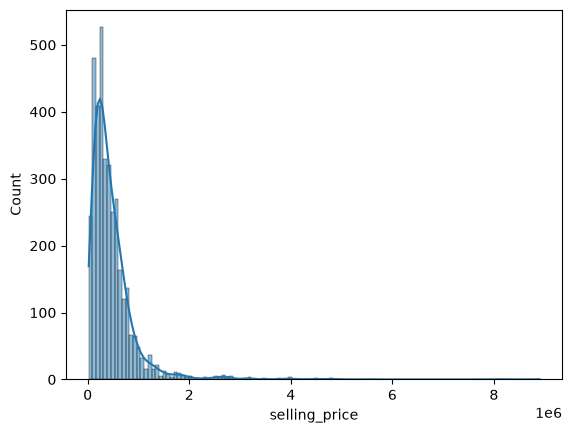

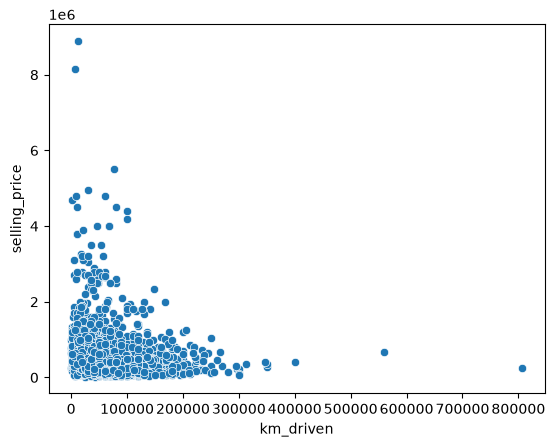

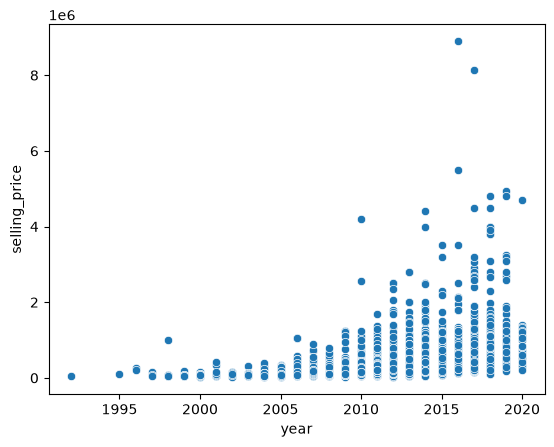

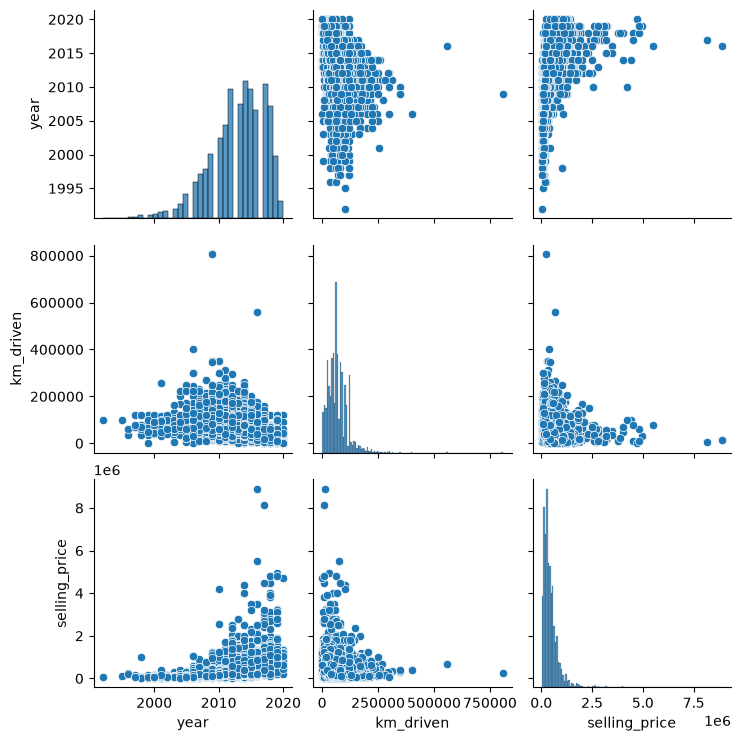

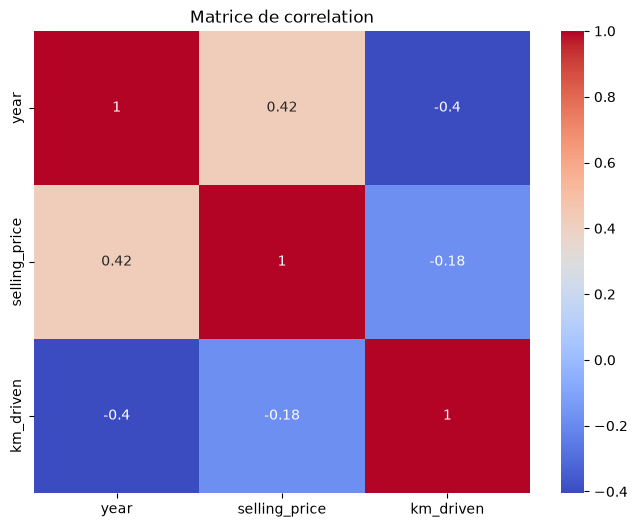

(3672, 8)
x_train : (2937, 6)
X_test : (735, 6)
y_train : (2937,)
y_test : (735,)
Avant transformation : (2937, 6)
Après transformation : (2937, 16)


In [2]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split


from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline


data=pd.read_csv('../data/car-price.csv')
# print(data)

# infos
print(data.head())
print(data.shape)#nbr ligne +colone
print(data.describe())

print(data.dtypes)
print(data.columns)
data.info()

# null
print(data.isna().sum())

# remplissage des valeur null
data["year"]=data["year"].fillna(data["year"].median())
data["km_driven"]=data["km_driven"].fillna(data['km_driven'].median())
data["fuel"]=data["fuel"].fillna(data["fuel"].mode()[0])
data["seller_type"]=data["seller_type"].fillna(data["seller_type"].mode()[0])
data["owner"]=data["owner"].fillna(data["owner"].mode()[0])

# print(data.isna().sum())

# duplicate
print(data.duplicated().sum())
data.drop_duplicates(inplace=True)


# changement du type
data['year']=data['year'].astype(int)
data["selling_price"]=data["selling_price"].astype(float)




# la relation entre les variable
sns.histplot(data["selling_price"],kde=True)#kde ligne entre les points
plt.show()

# Detecter les valeurs aberrantes(outlirs)
sns.scatterplot(data=data,x="km_driven",y="selling_price")
plt.show()

sns.scatterplot(data=data,x=data["year"],y=data["selling_price"])
plt.show()

# les relation entre les var numerique
sns.pairplot(data[['year','km_driven','selling_price']])
plt.show()

# correlation
plt.figure(figsize=(8, 6))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Matrice de correlation")

plt.show()

# outliers
# def detect_outliers(column):
#     Q1=data[column].quantile(0.25)
#     Q3=data[column].quantile(0.75)

#     IQR=Q3-Q1
#     lower=Q1-1.5*IQR
#     upper=Q3+1.5*IQR

#     outliers=data[
#         (data[column] < lower) |
#         (data[column] > upper)
#     ]

#     # print(column)
#     print("limite inferieure :",lower)
#     print("limite superieure :",upper)

#     print("nbr outliers :",len(outliers))

#     print("\nQuelques outliers :")
#     print(outliers.head(10))

#     return lower,upper


# detect_outliers("year")
# detect_outliers("km_driven")
# detect_outliers("selling_price")



def clip_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[column] = df[column].clip(lower=lower, upper=upper)
    return df
 
data = clip_outliers(data, "km_driven")
data = clip_outliers(data, "selling_price")


# print(data[data["km_driven"]<0])
# print(data[data["year"]>2026])
# print(data[data["selling_price"]<0])

# corriger les outliers
# ramener a la limite acceptable
# lower,upper=detect_outliers("km_driven")
# data["km_driven"]=data["km_driven"].clip(lower=lower,upper=upper)



# encoder
# x=les info utilisee pour predire & y=ce quon veut predire

X=data.drop(["selling_price","name"],axis=1)
Y=data["selling_price"]

# print(Y.name)#serie
# print(X.columns)


# One-Hot Encoding = > crrer des colonne pour chaque categorie

# pd.set_option('display.max_columns',None)#pour voir tous les columns
# methode 1
# print(X.head())
# # print(X.shape)
# x=pd.get_dummies(X)
# print(X.shape)

# methode 2

categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]
numeric_columns=[
    "year",
    "km_driven"
]
# transformation des colones
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numeric_columns),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_columns)#ignore new categ
    ]
)


# x_encoder=encoder.fit_transform(x[categorical_columns])

# Test / Train
X_train,X_test,Y_train,Y_test=train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)


X_train_encoded=preprocessor.fit_transform(X_train)
X_test_encoded=preprocessor.transform(X_test)

print(data.shape)
print("x_train :",X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", Y_train.shape)
print("y_test :", Y_test.shape)


print("Avant transformation :", X_train.shape)
print("Après transformation :", X_train_encoded.shape)


In [3]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

model=Pipeline([
    ("preprocessor",preprocessor),#avant dentrainer le model, transforme les donne (StandardScaler,OneHotEncoder)
    ("model",LinearRegression())
])

model.fit(X_train,Y_train)#apprendre apartir des donne
Y_predict=model.predict(X_test)


mae=mean_absolute_error(Y_test,Y_predict)
rmse=np.sqrt(mean_squared_error(Y_test,Y_predict))
r2=r2_score(Y_test,Y_predict)

print("MAE :",mae)
print("RMSE :",rmse)
print("R2 :",r2)


MAE : 154630.39975232008
RMSE : 205048.31269517296
R2 : 0.5714349014313272


In [4]:
from sklearn.ensemble import RandomForestRegressor
model_rf=Pipeline([
    ("preprocessor",preprocessor),
    ("model",RandomForestRegressor(random_state=42))
])
model_rf.fit(X_train,Y_train)
predict_rf=model_rf.predict(X_test)
mea_rf=mean_absolute_error(Y_test,predict_rf)
mse_rf=mean_squared_error(Y_test,predict_rf)
rmse_rf=np.sqrt(mse_rf)
r2_rf=r2_score(Y_test,predict_rf)
print("random forest")
print("_________")
print("MAE :",mea_rf)
print("MSE :",mse_rf)
print("RMSE :",rmse_rf)
print("R2 :",r2_rf)

random forest
_________
MAE : 144506.8630052149
MSE : 41877855923.35232
RMSE : 204640.79730921768
R2 : 0.5731366791407033


In [5]:
from xgboost import XGBRegressor
model_xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(random_state=42))
])

model_xgb.fit(X_train, Y_train)

Y_predict_xgb = model_xgb.predict(X_test)

mae_xgb = mean_absolute_error(Y_test, Y_predict_xgb)
mse_xgb = mean_squared_error(Y_test, Y_predict_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(Y_test, Y_predict_xgb)

print("XGBoost")
print("MAE  :", mae_xgb)
print("RMSE :", rmse_xgb)
print("R2   :", r2_xgb)

XGBoost
MAE  : 142311.80271361474
RMSE : 200087.96457051777
R2   : 0.5919190393105525


In [6]:
from sklearn.svm import SVR
model_svr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVR())
])

model_svr.fit(X_train, Y_train)

Y_predict_svr = model_svr.predict(X_test)

mae_svr = mean_absolute_error(Y_test, Y_predict_svr)
mse_svr = mean_squared_error(Y_test, Y_predict_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(Y_test, Y_predict_svr)

print("SVR")
print("MAE  :", mae_svr)
print("RMSE :", rmse_svr)
print("R2   :", r2_svr)

SVR
MAE  : 239888.56092546182
RMSE : 326643.98914016975
R2   : -0.08756129168202342


In [7]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "SVR"
    ],
    "MAE": [
        mae,
        mea_rf,
        mae_xgb,
        mae_svr
    ],
    "RMSE": [
        rmse,
        rmse_rf,
        rmse_xgb,
        rmse_svr
    ],
    "R2": [
        r2,
        r2_rf,
        r2_xgb,
        r2_svr
    ]
})

print(results)

               Model            MAE           RMSE        R2
0  Linear Regression  154630.399752  205048.312695  0.571435
1      Random Forest  144506.863005  204640.797309  0.573137
2            XGBoost  142311.802714  200087.964571  0.591919
3                SVR  239888.560925  326643.989140 -0.087561


In [8]:
# one_car = X_test.iloc[[0]]
# real_price = Y_test.iloc[0]

# prediction_linear = model.predict(one_car)[0]

# prediction_rf = model_rf.predict(one_car)[0]

# prediction_xgb = model_xgb.predict(one_car)[0]

# prediction_svr = model_svr.predict(one_car)[0]

# print("Prix reel :", real_price)

# print("\nPrédictions :")
# print("Linear Regression :", prediction_linear)
# print("Random Forest     :", prediction_rf)
# print("XGBoost           :", prediction_xgb)
# print("SVR               :", prediction_svr)


In [9]:
# l'optimisation
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

rf_pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ("model",RandomForestRegressor(random_state=1))
])

rf_param_grid={
    "model__n_estimators":[200,300,500],#nombre d'arbre
    "model__max_depth":[10,15,30,None],#profondeur max dune arbre
    "model__min_samples_split":[2,5,10]#nbr min d'observation necessaire pour diviser un noeud
}

grid_rf=GridSearchCV(
    estimator=rf_pipeline,#le model
    param_grid=rf_param_grid,#hyper
    cv=5,#validation groise 5 folds
    scoring="r2",#cherche la combin ayant le meilleur rmse
    n_jobs=-1#utiliser tous les coeur dispo pour accelerer la recherche
)
grid_rf.fit(X_train,Y_train)
print("meilleurs parametres RandomForest :")
print(grid_rf.best_params_)
print("Meilleur RMSE CV Random Forest :", -grid_rf.best_score_)

print("Meilleur score CV :")
print(-grid_rf.best_score_)

best_rf = grid_rf.best_estimator_#recuperer le meilleur model
Y_predict_rf_optimized=best_rf.predict(X_test) 

mea_rf_opti=mean_absolute_error(
    Y_test,
    Y_predict_rf_optimized
)

mse_rf_opti=mean_squared_error(
    Y_test,
    Y_predict_rf_optimized
)
rmse_rf_opti=np.sqrt(mse_rf_opti)

r2_rf_opti=r2_score(
    Y_test,
    Y_predict_rf_optimized
)

print("Random Forest optimisé")
print("-------------------------")
print("MAE  :", mea_rf_opti)
print("RMSE :", rmse_rf_opti)
print("R2   :", r2_rf_opti) 

meilleurs parametres RandomForest :
{'model__max_depth': 10, 'model__min_samples_split': 10, 'model__n_estimators': 500}
Meilleur RMSE CV Random Forest : -0.5844782180237772
Meilleur score CV :
-0.5844782180237772
Random Forest optimisé
-------------------------
MAE  : 135145.43068346713
RMSE : 188782.0938034334
R2   : 0.6367329580684526


In [10]:
#xgb
xgb_pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ("model",XGBRegressor(random_state=1))
])

xgb_param_grid={
    "model__learning_rate":[0.01,0.05,0.1],#la vitese a laquelle le modele apprend
    "model__max_depth":[3,5,7],
    "model__subsample":[0.8,1.0]#
}

grid_xgb=GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)
grid_xgb.fit(X_train, Y_train)

#
print("Meilleurs paramètres XGBoost :")
print(grid_xgb.best_params_) 
print("Meilleur RMSE CV :", -grid_xgb.best_score_)

best_xgb=grid_xgb.best_estimator_

Y_predict_xgb_opti=best_xgb.predict(X_test)
mae_xgb_opti = mean_absolute_error(
    Y_test,
    Y_predict_xgb_opti
)

mse_xgb_opti = mean_squared_error(
    Y_test,
    Y_predict_xgb_opti
)

rmse_xgb_opti = np.sqrt(mse_xgb_opti)

r2_xgb_opti = r2_score(
    Y_test,
    Y_predict_xgb_opti
)

print("XGBoost optimise")
print("-------------------------")
print("MAE  :", mae_xgb_opti)
print("RMSE :", rmse_xgb_opti)
print("R2   :", r2_xgb_opti)

Meilleurs paramètres XGBoost :
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__subsample': 0.8}
Meilleur RMSE CV : -0.6114000436078417
XGBoost optimise
-------------------------
MAE  : 133435.34552508502
RMSE : 185605.1353402482
R2   : 0.6488567078071454


In [11]:
comparaison=pd.DataFrame({
    "model":[
        "randomForest - avant",
        "randomForest - apres",
        "xgboost - avant",
        "xgboost - apres",
    ],
    "Mae":[
        mea_rf,
        mea_rf_opti,
        mae_xgb,
        mae_xgb_opti
    ],
    "RMSE" :[
        rmse_rf,
        rmse_rf_opti,
        rmse_xgb,
        rmse_xgb_opti
    ],
    "R2":[
        r2_rf,
        r2_rf_opti,
        r2_xgb,
        r2_xgb_opti
    ]
})

print(comparaison)

                  model            Mae           RMSE        R2
0  randomForest - avant  144506.863005  204640.797309  0.573137
1  randomForest - apres  135145.430683  188782.093803  0.636733
2       xgboost - avant  142311.802714  200087.964571  0.591919
3       xgboost - apres  133435.345525  185605.135340  0.648857


In [12]:
# predictions des modeles deja entraines

Y_predict_linear = model.predict(X_test)
Y_predict_rf = model_rf.predict(X_test)
Y_predict_xgb = model_xgb.predict(X_test)
Y_predict_svr = model_svr.predict(X_test)
# opti
Y_predict_rf_optimized = best_rf.predict(X_test)
Y_predict_xgb_optimized = best_xgb.predict(X_test)

In [13]:
resultat_final=pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "SVR",
        "Random Forest Optimized",
        "XGBoost Optimized"
    ],
    "Mae":[
        mean_absolute_error(Y_test,Y_predict_linear),
        mean_absolute_error(Y_test,Y_predict_rf),
        mean_absolute_error(Y_test,Y_predict_xgb),
        mean_absolute_error(Y_test,Y_predict_svr),
        mean_absolute_error(Y_test,Y_predict_rf_optimized),
        mean_absolute_error(Y_test,Y_predict_xgb_optimized),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test,Y_predict_linear)),
        np.sqrt(mean_squared_error(Y_test,Y_predict_rf)),
        np.sqrt(mean_squared_error(Y_test,Y_predict_xgb)),
        np.sqrt(mean_squared_error(Y_test,Y_predict_svr)),
        np.sqrt(mean_squared_error(Y_test,Y_predict_rf_optimized)),
        np.sqrt(mean_squared_error(Y_test,Y_predict_xgb_optimized))
    ],
    "R2": [
        r2_score(Y_test,Y_predict_linear),
        r2_score(Y_test,Y_predict_rf),
        r2_score(Y_test,Y_predict_xgb),
        r2_score(Y_test,Y_predict_svr),
        r2_score(Y_test,Y_predict_rf_optimized),
        r2_score(Y_test,Y_predict_xgb_optimized)
    ]
})

# print(resultat_final)
resultat_final_sorted=resultat_final.sort_values(
    by="RMSE",
    ascending=True
)
print(resultat_final_sorted)

                     Model            Mae           RMSE        R2
5        XGBoost Optimized  133435.345525  185605.135340  0.648857
4  Random Forest Optimized  135145.430683  188782.093803  0.636733
2                  XGBoost  142311.802714  200087.964571  0.591919
1            Random Forest  144506.863005  204640.797309  0.573137
0        Linear Regression  154630.399752  205048.312695  0.571435
3                      SVR  239888.560925  326643.989140 -0.087561


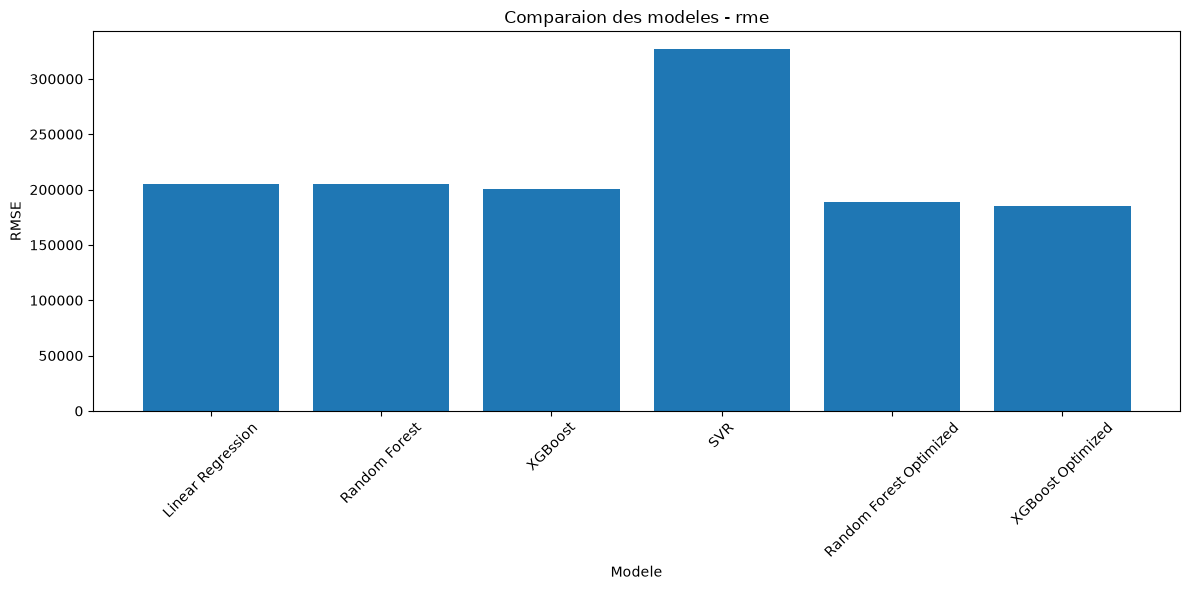

In [14]:
# rmse
plt.figure(figsize=(12,6))

plt.bar(
    resultat_final["Model"],
    resultat_final["RMSE"],
)

plt.xlabel("Modele")
plt.ylabel("RMSE")
plt.title("Comparaion des modeles - rme")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


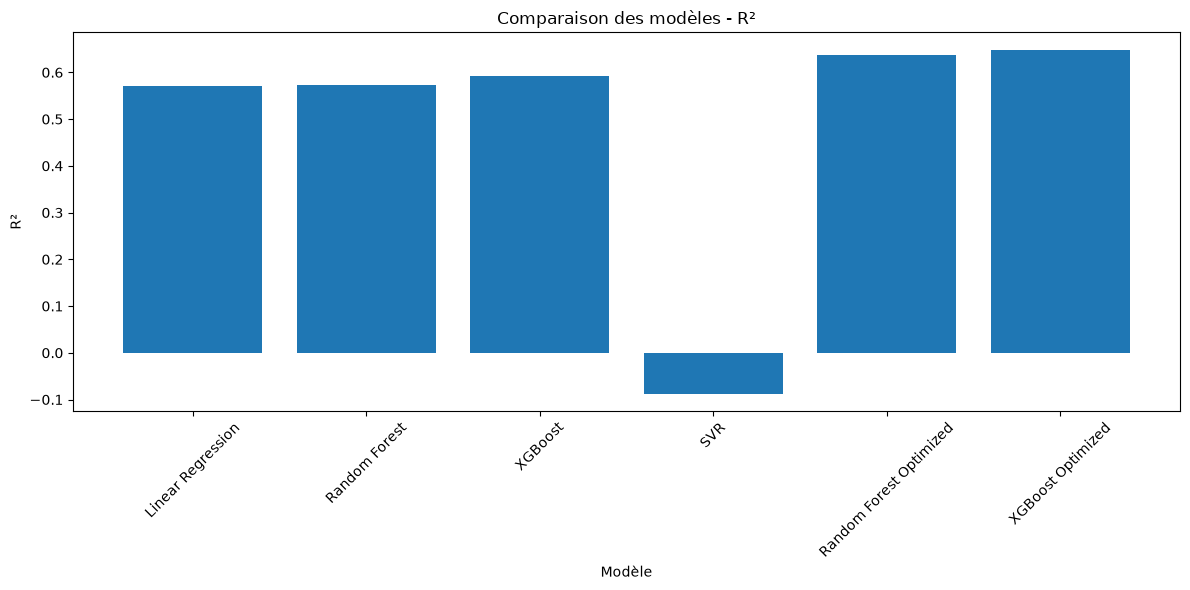

In [15]:
# r2
plt.figure(figsize=(12, 6))

plt.bar(
    resultat_final["Model"],
    resultat_final["R2"]
)

plt.xlabel("Modèle")
plt.ylabel("R²")
plt.title("Comparaison des modèles - R²")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

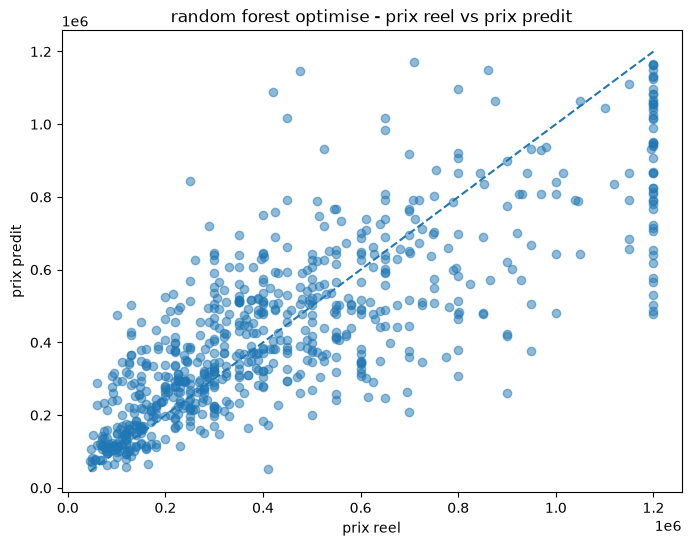

In [16]:
# scatter plot predic vs valeurs reel

plt.figure(figsize=(8,6))

plt.scatter(
    Y_test,
    Y_predict_rf_optimized,
    alpha=0.5
)
# 
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    linestyle="--"
)
# 

plt.xlabel("prix reel")
plt.ylabel("prix predit")
plt.title("random forest optimise - prix reel vs prix predit")
plt.show()

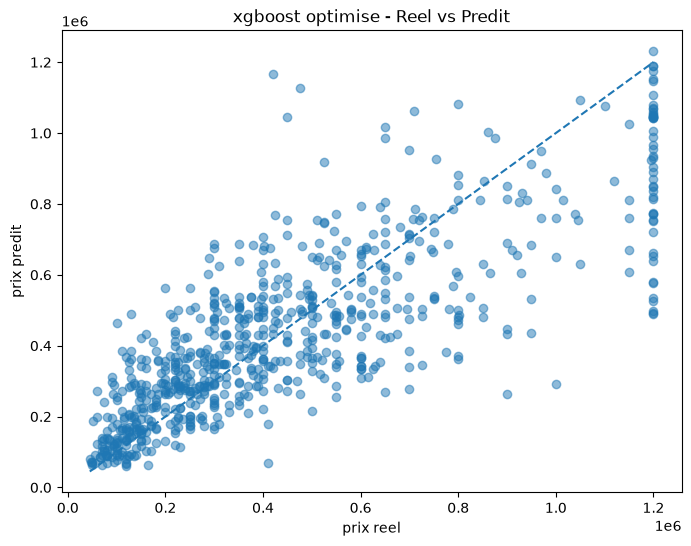

In [17]:
# graphe pour xg boost
plt.figure(figsize=(8,6))

plt.scatter(
    Y_test,
    Y_predict_xgb_optimized,
    alpha=0.5
)
plt.plot(
    [Y_test.min(),Y_test.max()],
    [Y_test.min(),Y_test.max()],
    linestyle="--"
)
plt.xlabel("prix reel")
plt.ylabel("prix predit")
plt.title("xgboost optimise - Reel vs Predit")

plt.show()

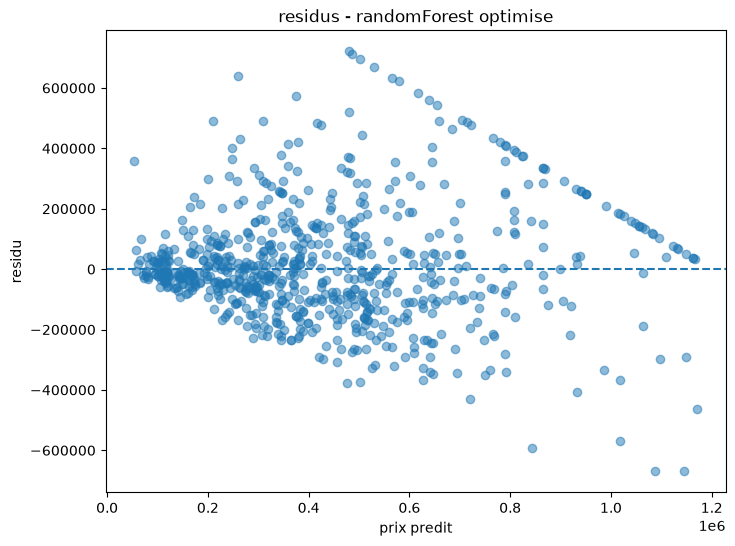

In [18]:
# calculer le residu

residu_rf=Y_test - Y_predict_rf_optimized
residu_xgb=Y_test - Y_predict_xgb_optimized

# print(residu_rf)
# print(residu_xgb)

plt.figure(figsize=(8,6))

plt.scatter(
    Y_predict_rf_optimized,
    residu_rf,
    alpha=0.5
)
plt.axhline(
    y=0,
    linestyle="--"
)
plt.xlabel("prix predit")
plt.ylabel("residu")
plt.title("residus - randomForest optimise")

plt.show()


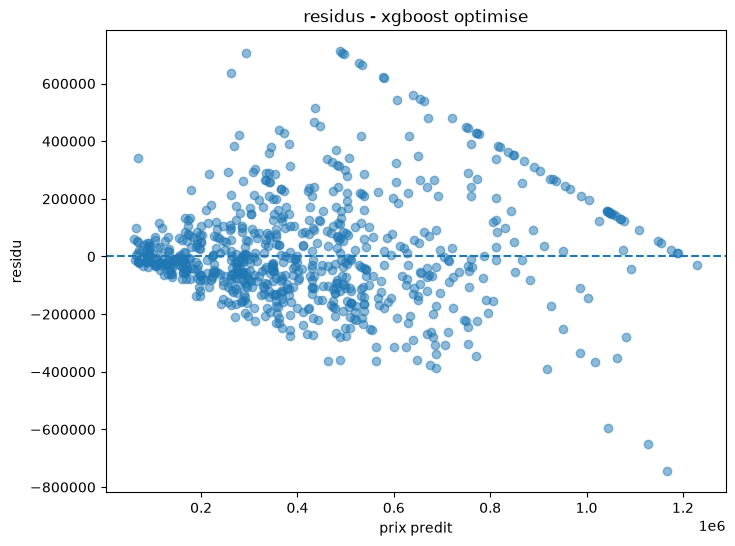

In [19]:
# xgb
plt.figure(figsize=(8, 6))

plt.scatter(
    Y_predict_xgb_optimized,
    residu_xgb,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("prix predit")
plt.ylabel("residu")
plt.title("residus - xgboost optimise")

plt.show()

In [20]:
variance_rf=np.var(residu_rf)
variance_xgb=np.var(residu_xgb)

print("la variance des erreurs RandomForest :", variance_rf)
print("la variance des erreurs XGBoost :", variance_xgb)    

la variance des erreurs RandomForest : 35529691429.40195
la variance des erreurs XGBoost : 34322844235.160114


In [21]:
# df
optimized_results = pd.DataFrame({
    "Model": [
        "Random Forest Optimized",
        "XGBoost Optimized"
    ],

    "MAE": [
        mea_rf_opti,
        mae_xgb_opti
    ],

    "RMSE": [
        rmse_rf_opti,
        rmse_xgb_opti
    ],

    "R2": [
        r2_rf_opti,
        r2_xgb_opti
    ],

    "error_variance": [
        variance_rf,
        variance_xgb
    ]
})

print(optimized_results)

                     Model            MAE           RMSE        R2  \
0  Random Forest Optimized  135145.430683  188782.093803  0.636733   
1        XGBoost Optimized  133435.345525  185605.135340  0.648857   

   error_variance  
0    3.552969e+10  
1    3.432284e+10  


In [22]:

# Sauvegarder le modèle final pour la réutilisation plus tard
import os
import joblib

# Créer le dossier model s'il n'existe pas
os.makedirs("../model", exist_ok=True)

# Sauvegarder le modèle
joblib.dump(
    best_xgb,
    "../model/car_price_model.pkl"
)

print("Modèle sauvegardé avec succès !")


Modèle sauvegardé avec succès !


In [23]:
# recharger le model
load_model=joblib.load("../model/car_price_model.pkl")
print("done")

done


In [24]:
# exemple de test
new_car=pd.DataFrame({
    "year": [2018],
    "km_driven": [50000],
    "fuel": ["Petrol"],
    "seller_type": ["Individual"],
    "transmission": ["Manual"],
    "owner": ["First Owner"],
})

predicted_price=load_model.predict(new_car)
print("prix estime :",predicted_price)

prix estime : [466586.97]


In [25]:
load_model=joblib.load("../model/car_price_model.pkl")
print(load_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['year', 'km_driven']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['fuel', 'seller_type',
                                                   'transmission',
                                                   'owner'])])),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=None, device=None...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              int

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = load_model.predict(X_test)

mae = mean_absolute_error(Y_test, y_pred)
rmse = np.sqrt(mean_squared_error(Y_test, y_pred))
r2 = r2_score(Y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)


MAE : 133435.34552508502
RMSE: 185605.1353402482
R²  : 0.6488567078071454
